# Dados e Aprendizagem Automática 26/27
### Part VII

Install ipywidgets and shap

### Imports and installations

In [1]:
!pip install shap

import sklearn as skl
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import shap

from sklearn import linear_model
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import  train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
%matplotlib inline

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 555.9/555.9 kB 1.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [shap]3/4 [shap]r]


/home/ivocs/miniconda3/envs/daa_env/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## FE and EDA on Titanic Dataset

Load the CSV - *Titanic*

In [2]:
df = pd.read_csv("titanic.csv")

Inspect data

In [3]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


Plot the distribution of *Age*, *SibSp*, *Parch*, and *Fare*

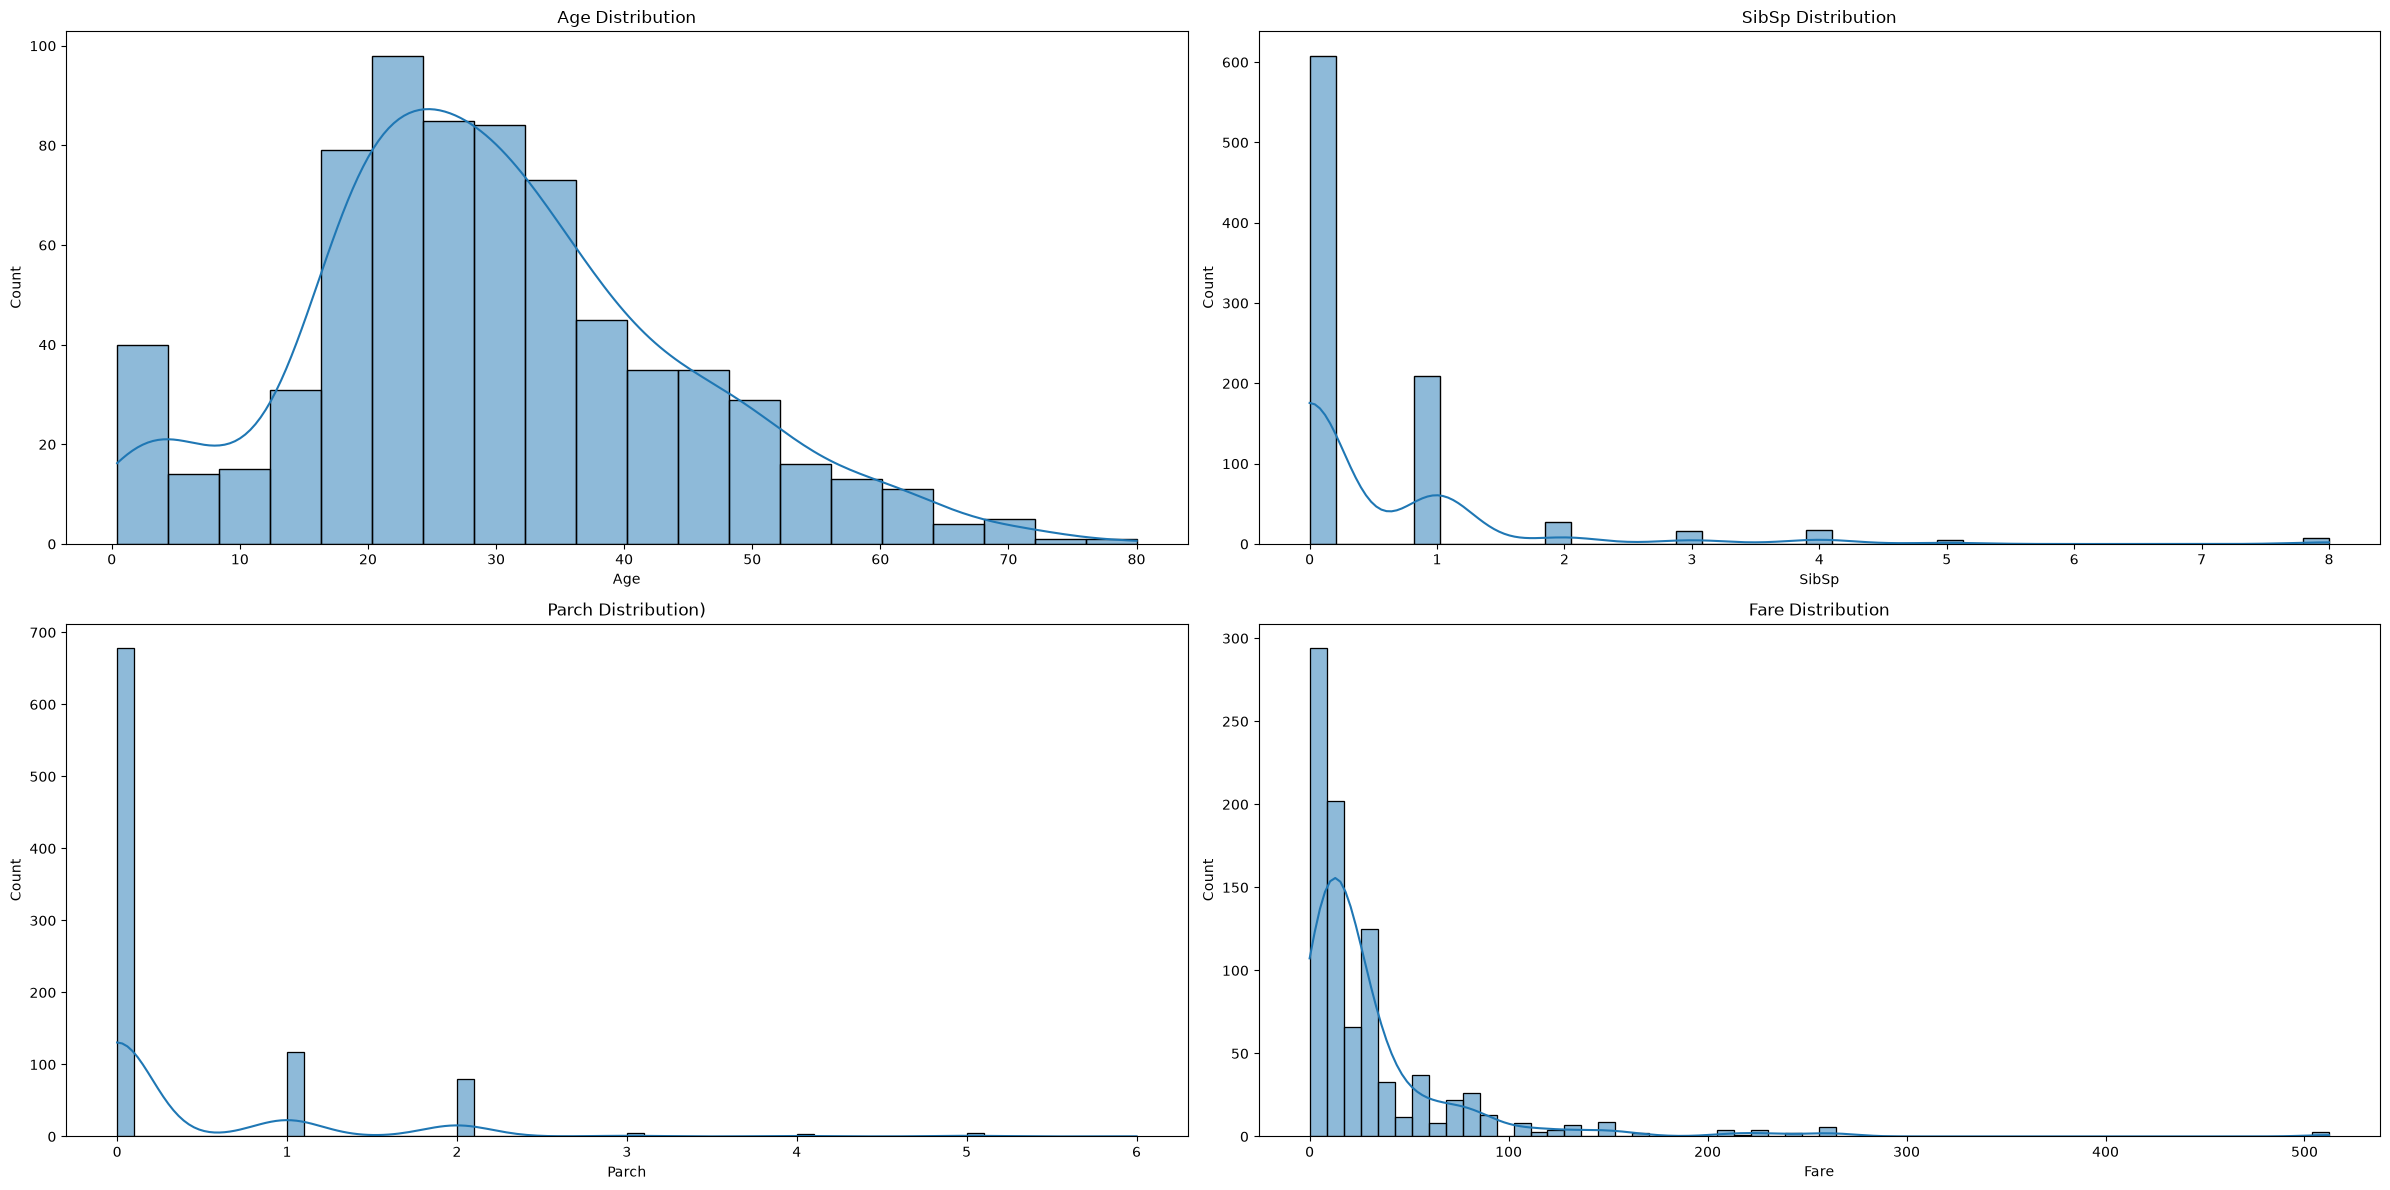

In [6]:
# Set up the figure and axes
fig, axes = plt.subplots(2, 2, figsize=(24, 12))

# Age Distribution
sns.histplot(data=df, x='Age', kde=True, ax=axes[0, 0])
axes[0, 0].set_title('Age Distribution')

# SibSp Distribution
sns.histplot(data=df, x='SibSp', kde=True, ax=axes[0, 1])
axes[0, 1].set_title('SibSp Distribution')

# Parch Distribution
sns.histplot(data=df, x='Parch', kde=True, ax=axes[1, 0])
axes[1, 0].set_title('Parch Distribution)')

# Fare Distribution
sns.histplot(data=df, x='Fare', kde=True, ax=axes[1, 1])
axes[1, 1].set_title('Fare Distribution')

plt.tight_layout()
plt.show()

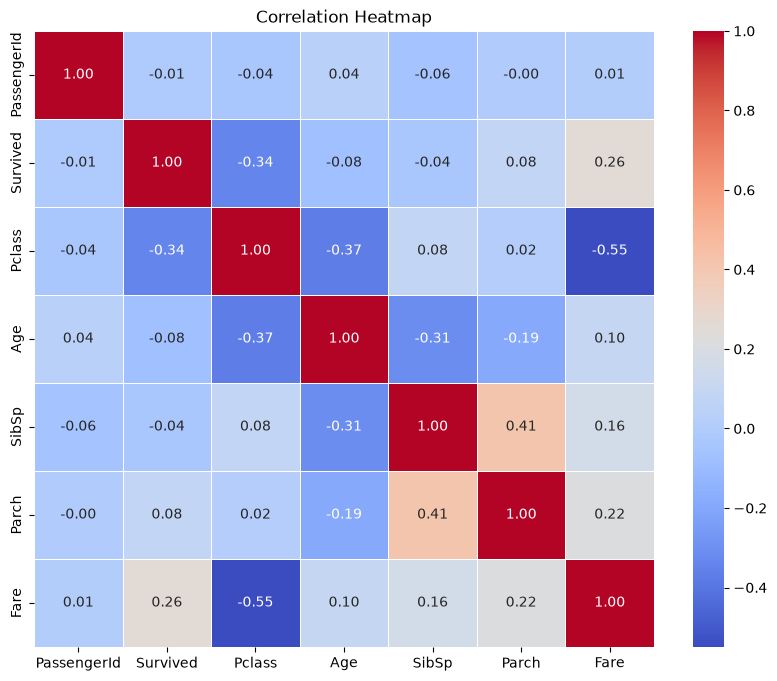

In [7]:
df2 = df.drop(['Name', 'Sex', 'Ticket', 'Cabin', 'Embarked'], axis = 1)
correlation_matrix = df2.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap')
plt.show()

Missing values

<Axes: >

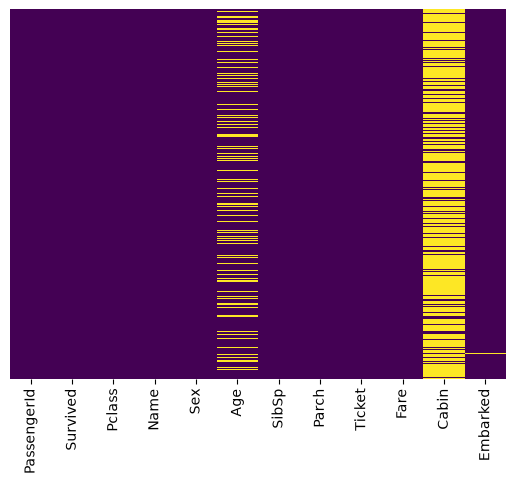

In [10]:
sns.heatmap(df.isnull(), yticklabels=False, cbar=False, cmap='viridis')

In [8]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

Feature *Age*

In [11]:
def med_impute_nan(df):
    med_impute = df.copy()
    med_impute['Age'] = med_impute['Age'].fillna(med_impute['Age'].median())
    return med_impute

In [12]:
med_impute = med_impute_nan(df)

In [13]:
med_impute.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [14]:
med_impute.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [15]:
# checking standard deviation
print(df['Age'].std())
print(med_impute['Age'].std())

14.526497332334042
13.019696550973201


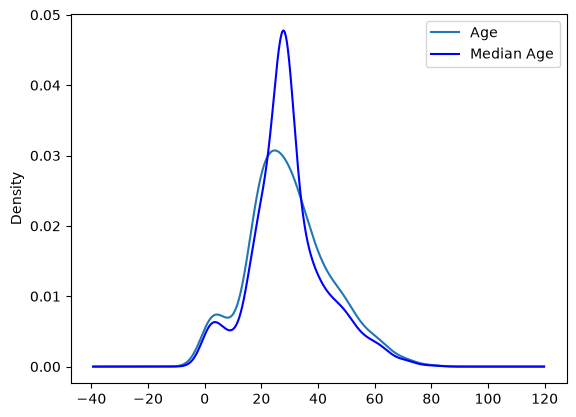

In [16]:
# plotting the variance difference
fig = plt.figure()
ax = fig.add_subplot(111)
df['Age'].plot(kind='kde', ax=ax)
med_impute['Age'].plot(kind='kde', label='Median Age', ax=ax, color='blue')
lines, labels = ax.get_legend_handles_labels()
ax.legend(lines, labels, loc='best')

In [17]:
df = med_impute
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

Feature *Embarked*

In [79]:
df.Embarked.value_counts

<bound method IndexOpsMixin.value_counts of 0      2
1      0
2      2
3      2
4      2
      ..
886    2
887    2
888    2
889    0
890    1
Name: Embarked, Length: 891, dtype: int64>

In [80]:
emabark = df['Embarked'].dropna

In [82]:
df[df['Embarked'].isnull()]

,PassengerId,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked


In [83]:
df['Embarked'].mode

<bound method Series.mode of 0      2
1      0
2      2
3      2
4      2
      ..
886    2
887    2
888    2
889    0
890    1
Name: Embarked, Length: 891, dtype: int64>

In [85]:
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])

In [86]:
df[df['Embarked'].isnull()]

,PassengerId,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked


In [87]:
df.isnull().sum()

PassengerId    0
Survived       0
Pclass         0
Sex            0
Age            0
SibSp          0
Parch          0
Fare           0
Embarked       0
dtype: int64

Feature *Cabin*

In [18]:
df['Cabin'].value_counts

<bound method IndexOpsMixin.value_counts of 0       NaN
1       C85
2       NaN
3      C123
4       NaN
       ... 
886     NaN
887     B42
888     NaN
889    C148
890     NaN
Name: Cabin, Length: 891, dtype: str>

In [19]:
df['Cabin'].mode()

0        B96 B98
1    C23 C25 C27
2             G6
Name: Cabin, dtype: str

In [20]:
df['Cabin'] = df['Cabin'].fillna(df['Cabin'].mode()[0])

In [21]:
df.isnull().sum()

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Cabin          0
Embarked       2
dtype: int64

In [22]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,B96 B98,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,B96 B98,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,B96 B98,S


Feature *Sex* 

In [23]:
df['Sex'] = df['Sex'].apply(lambda x: 1 if x == 'male' else 0)
df.Sex


0      1
1      0
2      0
3      0
4      1
      ..
886    1
887    0
888    0
889    1
890    1
Name: Sex, Length: 891, dtype: int64

In [24]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",1,22.0,1,0,A/5 21171,7.2500,B96 B98,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",0,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",0,26.0,0,0,STON/O2. 3101282,7.9250,B96 B98,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",0,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",1,35.0,0,0,373450,8.0500,B96 B98,S


Features *Name*, *Ticket* and *Cabin* 

In [27]:
df.drop(columns=['Name', 'Ticket', 'Cabin'], inplace=True)

In [28]:
df.head()

,PassengerId,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,1,0,3,1,22.0,1,0,7.2500,S
1,2,1,1,0,38.0,1,0,71.2833,C
2,3,1,3,0,26.0,0,0,7.9250,S
3,4,1,1,0,35.0,1,0,53.1000,S
4,5,0,3,1,35.0,0,0,8.0500,S


Feature *Embarked* 

In [30]:
print(df["Embarked"].value_counts)

<bound method IndexOpsMixin.value_counts of 0      S
1      C
2      S
3      S
4      S
      ..
886    S
887    S
888    S
889    C
890    Q
Name: Embarked, Length: 891, dtype: str>


In [31]:
cols = ['Embarked']
le = LabelEncoder()


for col in cols:
    df[col] = le.fit_transform(df[col])
df.head()

,PassengerId,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,1,0,3,1,22.0,1,0,7.2500,2
1,2,1,1,0,38.0,1,0,71.2833,0
2,3,1,3,0,26.0,0,0,7.9250,2
3,4,1,1,0,35.0,1,0,53.1000,2
4,5,0,3,1,35.0,0,0,8.0500,2


Correlation analysis of the features:

In [32]:
correlation_matrix = df.corr()
correlation_with_target = correlation_matrix['Survived'].sort_values(ascending=False)
print("Correlation with target (Survived):\n", correlation_with_target)

Correlation with target (Survived):
 Survived       1.000000
Fare           0.257307
Parch          0.081629
PassengerId   -0.005007
SibSp         -0.035322
Age           -0.064910
Embarked      -0.163517
Pclass        -0.338481
Sex           -0.543351
Name: Survived, dtype: float64


Save dataset into a new file

In [33]:
# Convert data to DataFrame
t = pd.DataFrame(df)

# Specify the CSV file name
filename = "titanic_ds.csv"

# Save to CSV
t.to_csv(filename, index=False, encoding='utf-8')

## Random Forest Classifier

Data split

In [34]:
X = df.drop('Survived', axis=1)
y = df['Survived']

In [35]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2022)

Train the model

In [36]:
rf_model = RandomForestClassifier() 

In [37]:
rf_model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

Accuracy of the model

In [40]:
rf_score = rf_model.score(X_test, y_test)
print("Accuracy: %.2f%%" % (rf_score * 100))

Accuracy: 82.84%


Save predictions to a file

In [41]:
op_rf = rf_model.predict(X_test)

In [42]:
op = pd.DataFrame(X_test['PassengerId'])
op['Survived'] = op_rf
op.to_csv("submission.csv", index=False)

## Feature Importance

Understanding which features influence predictions is fundamental. Feature importance analysis reveals the impact of factors like age, gender, and class on survival rates in theTitanic dataset.

### Random Forest Importance

In [44]:
start_time = time.time()

rf_importances = rf_model.feature_importances_
std = np.std([tree.feature_importances_ for tree in rf_model.estimators_], axis=0)

elapsed_time = time.time() - start_time

print(f"Elapsed time to compute the importances: {elapsed_time:.3f} seconds")

Elapsed time to compute the importances: 0.036 seconds


In [45]:
print("Random Forest Feature Importances:\n", rf_importances)

Random Forest Feature Importances:
 [0.17325632 0.08395251 0.23661943 0.1708702  0.05065549 0.04115575
 0.21129633 0.03219396]


In [46]:
rf_importances_df = pd.DataFrame({'Feature': X_test.columns, 'Gini Importance': rf_importances}).sort_values('Gini Importance', ascending=False)
print(rf_importances_df)

       Feature  Gini Importance
2          Sex         0.236619
6         Fare         0.211296
0  PassengerId         0.173256
3          Age         0.170870
1       Pclass         0.083953
4        SibSp         0.050655
5        Parch         0.041156
7     Embarked         0.032194


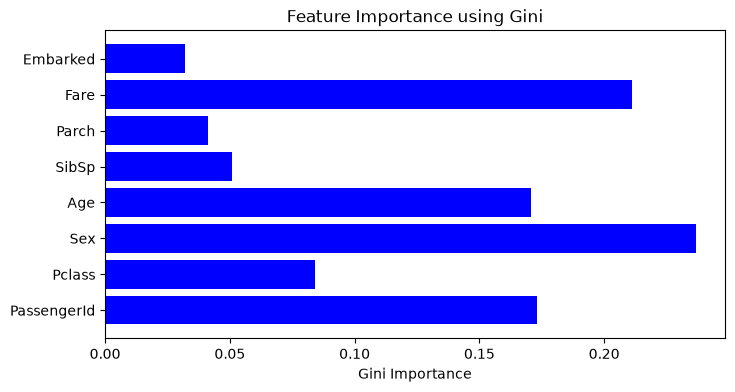

In [47]:
plt.figure(figsize=(8, 4))
plt.barh(X_test.columns, rf_importances, color='blue')
plt.xlabel('Gini Importance')
plt.title('Feature Importance using Gini')
plt.show()

### FI based on Mean Decrease in Impurity (MDI)

Feature importances are provided by the fitted attribute feature_importances_ and they are computed as the mean and standard deviation of accumulation of the impurity decrease within each tree.

In [48]:
start_time = time.time()

mdi_importances = pd.Series(rf_model.feature_importances_, index=X_test.columns)

elapsed_time = time.time() - start_time

print(f"Elapsed time to compute the importances: {elapsed_time:.3f} seconds")

Elapsed time to compute the importances: 0.029 seconds


In [49]:
print("Feature importances using MDI:\n", mdi_importances)

Feature importances using MDI:
 PassengerId    0.173256
Pclass         0.083953
Sex            0.236619
Age            0.170870
SibSp          0.050655
Parch          0.041156
Fare           0.211296
Embarked       0.032194
dtype: float64


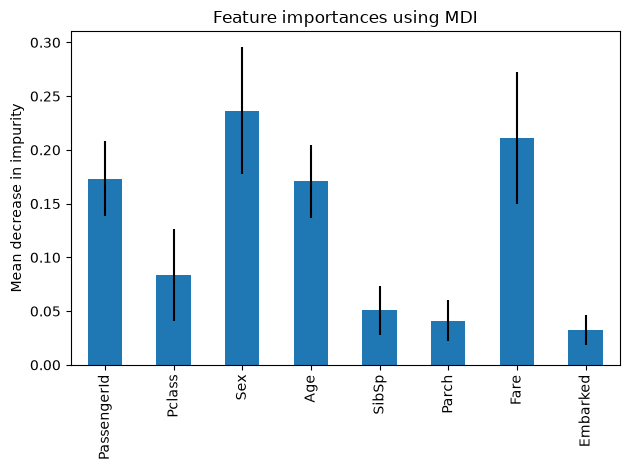

In [50]:
fig, ax = plt.subplots()
mdi_importances.plot.bar(yerr=std, ax=ax)
ax.set_title("Feature importances using MDI")
ax.set_ylabel("Mean decrease in impurity")
fig.tight_layout()

### FI based on Permutation Importance

Permutation feature importance overcomes limitations of the impurity-based feature importance: they do not have a bias toward high-cardinality features and can be computed on a left-out test set.

In [51]:
start_time = time.time()

result = permutation_importance(rf_model, X_test, y_test, n_repeats=10, random_state=42, n_jobs=2)

elapsed_time = time.time() - start_time
print(f"Elapsed time to compute the importances: {elapsed_time:.3f} seconds")

Elapsed time to compute the importances: 6.002 seconds


In [53]:
p_importances = pd.Series(result.importances_mean, index=X_test.columns)
print("Feature importances using PI:\n", p_importances)

Feature importances using PI:
 PassengerId    0.016791
Pclass         0.057463
Sex            0.169030
Age            0.023507
SibSp          0.013060
Parch          0.002985
Fare           0.063806
Embarked       0.005970
dtype: float64


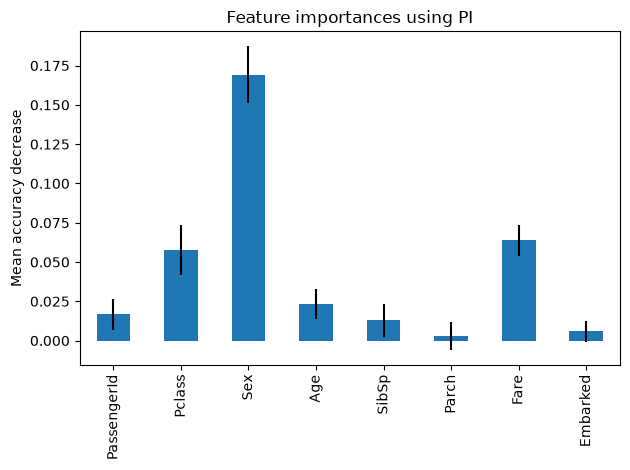

In [54]:
fig, ax = plt.subplots()
p_importances.plot.bar(yerr=result.importances_std, ax=ax)
ax.set_title("Feature importances using PI")
ax.set_ylabel("Mean accuracy decrease")
fig.tight_layout()
plt.show()

### Which features have more importance?

Model specific vs. model agnostic

## SHAP (SHapley Additive exPlanations) Analysis

<code>pip install shap</code>

<code>conda install -c conda-forge shap</code>

In [55]:
shap.initjs()

In [57]:
explainer = shap.TreeExplainer(rf_model)
shap_values = explainer(X_test)

### Local Interpretability

Local interpretability can be explained using the Titanic dataset. Let’s understand why a specific passenger, *ID=0*, didn't survived.

/home/ivocs/miniconda3/envs/daa_env/lib/python3.14/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


The passenger did not survive


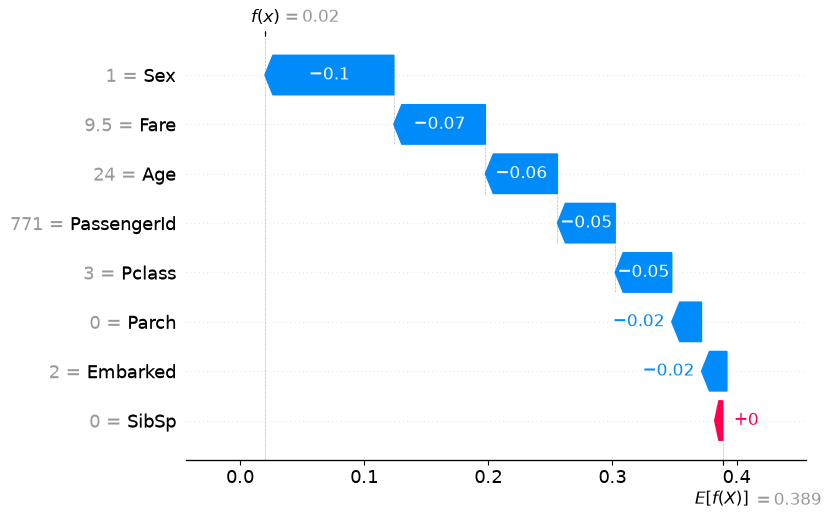

In [62]:
no = 0 # change the number for a different passenger analysis
if rf_model.predict(np.expand_dims(X_test.iloc[no],axis=0))[0] == 1:
    print("The passenger survived")
else:
    print("The passenger did not survive")
shap.plots.waterfall(shap_values[no,:,1])

### Global Interpretability

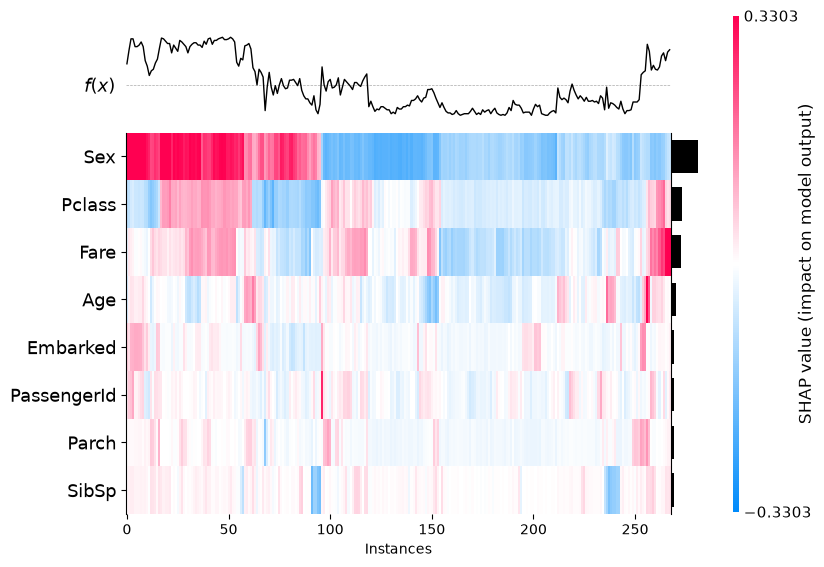

<Axes: xlabel='Instances'>

In [63]:
shap.plots.heatmap(shap_values[:,:,1])

### SHAP Analysis - Feature wise

This tells us how each feature globally contributed to the model prediction.

**Sex**

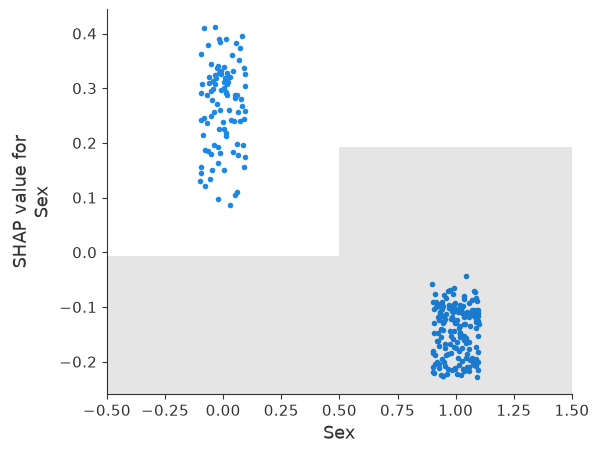

In [64]:
shap.plots.scatter(shap_values[:,"Sex",1])

**Pclass**

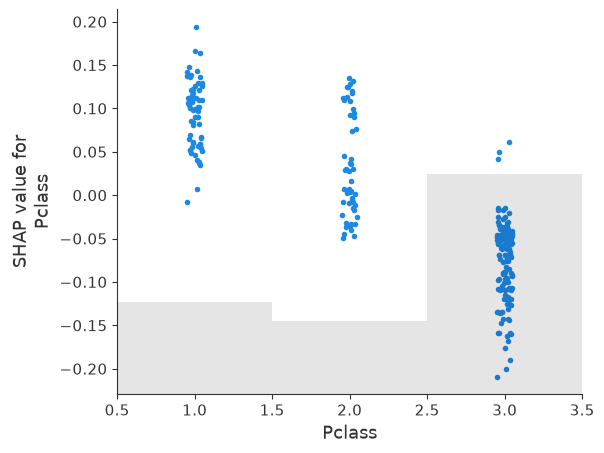

In [65]:
shap.plots.scatter(shap_values[:,"Pclass",1])

**Age**

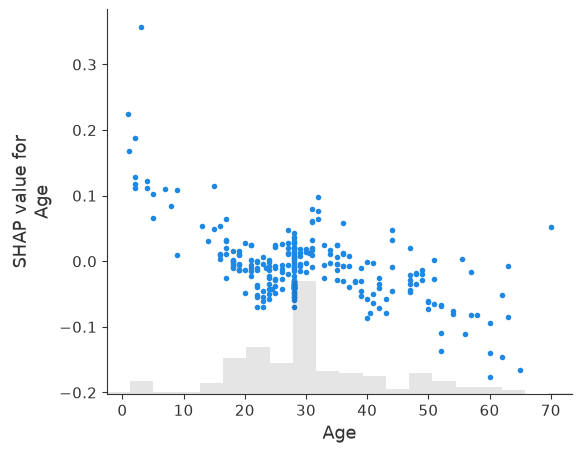

In [66]:
shap.plots.scatter(shap_values[:,"Age",1])

**Fare**

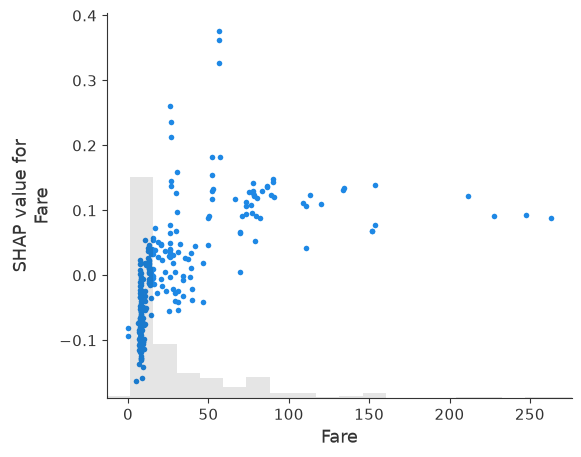

In [67]:
shap.plots.scatter(shap_values[:,"Fare",1])

**SibSp** and **Parch**

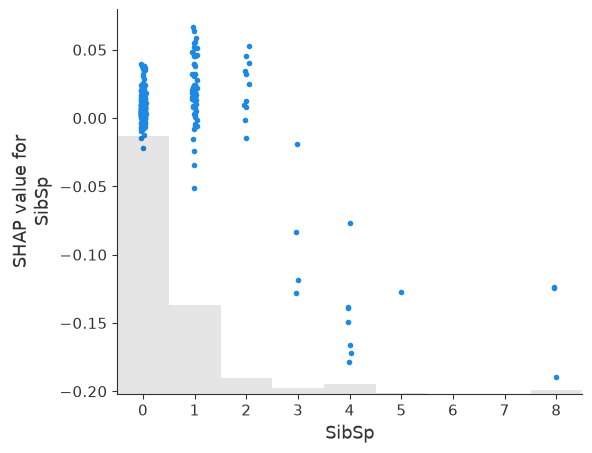

In [68]:
shap.plots.scatter(shap_values[:,"SibSp",1])

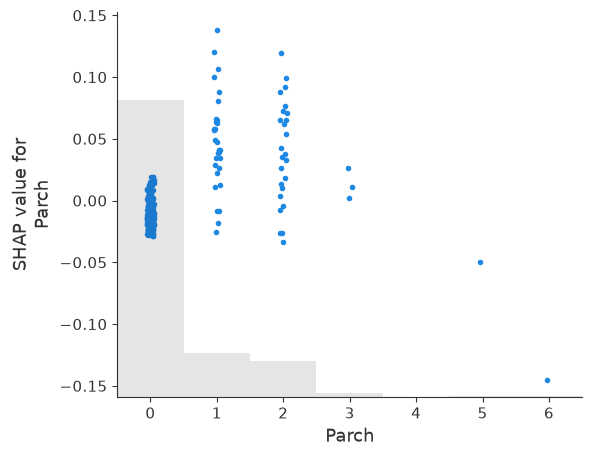

In [69]:
shap.plots.scatter(shap_values[:,"Parch",1])

**Global interpretability** is vital for comprehending overall model behavior. Using **Partial Dependence Plots (PDPs)** with the Titanic dataset, we can visualize how changes in *SibSp* influence the model’s predictions.

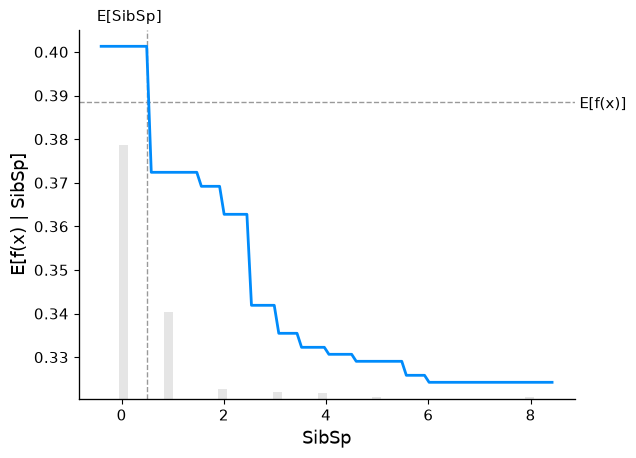

In [70]:
shap.partial_dependence_plot("SibSp", rf_model.predict, X_train, ice=False, model_expected_value=True, feature_expected_value=True,)

## Linear Regression

In [72]:
lm = linear_model.LinearRegression()
lm.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](8,)","[-0. ,-0.17,-0.49,..., 0. , 0. ,-0.02]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](8,)","['PassengerId','Pclass','Sex',...,'Parch','Fare','Embarked']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,1.349
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,8
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(8)


In [73]:
explainer = shap.LinearExplainer(lm, X_train)
shap_values = explainer.shap_values(X_train)

Background dataset has 623 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=623 when initializing the masker.


For one passenger:

In [74]:
shap.force_plot(explainer.expected_value, shap_values[0,:], X_test.iloc[0,:])

For all training data set:

In [75]:
explainer_shap = shap.LinearExplainer(model=lm, masker=X_train)
shap_values = explainer_shap.shap_values(X_train)

Background dataset has 623 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=623 when initializing the masker.


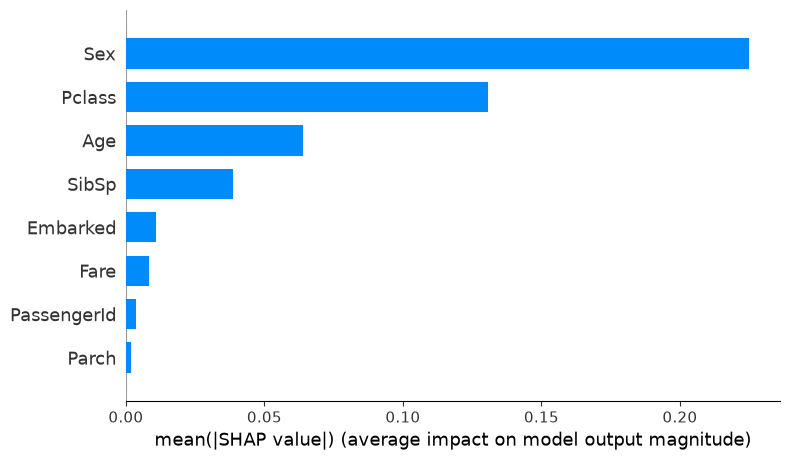

In [76]:
shap.summary_plot(shap_values, X_train, plot_type="bar")

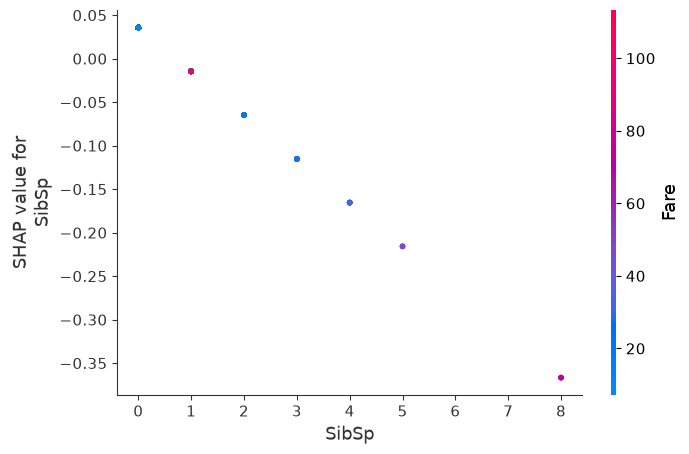

In [77]:
shap.dependence_plot("SibSp", shap_values, X_train)

Feature wise

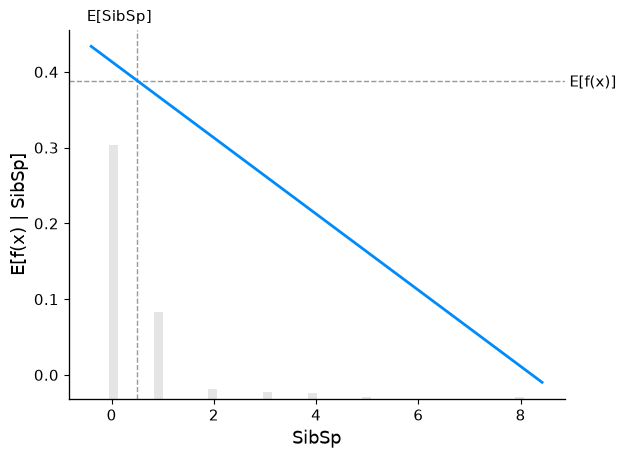

In [78]:
shap.partial_dependence_plot("SibSp", lm.predict, X_train, ice=False, 
                             model_expected_value=True, feature_expected_value=True,)